# 01 - قراءة الصور وتحويل الألوان وThresholding

يغطي هذا الدفتر أساسيات LAB1 وLAB2، ويحوّل الأكواد إلى وظائف منظمة يمكن نقل منطقها لاحقًا إلى Kotlin وOpenCV Android.

## أهداف الدفتر

- قراءة صورة وفحص خصائصها.
- فهم الفرق بين BGR وRGB.
- التحويل إلى Grayscale.
- التحويل إلى Binary باستخدام Threshold.
- مقارنة قيم Threshold مختلفة.
- تطبيق Threshold يدويًا باستخدام NumPy.
- حفظ النتائج.

In [1]:
from google.colab import drive
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

# ربط Google Drive
drive.mount("/content/drive")

# مسار المجلد الرئيسي للمشروع
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/"
    "VisionStudio_Android_ImageProcessing"
)

# مسارات الإدخال والنتائج
INPUT_DIR = PROJECT_ROOT / "02_Data/Images/Input"
TEST_DIR = PROJECT_ROOT / "02_Data/Images/Test"
OUTPUT_DIR = PROJECT_ROOT / "04_Outputs/Images"

# التأكد من وجود المجلدات
INPUT_DIR.mkdir(parents=True, exist_ok=True)
TEST_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# عرض المسارات للتأكد
print("Project folder:", PROJECT_ROOT)
print("Input folder:", INPUT_DIR)
print("Output folder:", OUTPUT_DIR)
print("Project exists:", PROJECT_ROOT.exists())

Mounted at /content/drive
Project folder: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing
Input folder: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/02_Data/Images/Input
Output folder: /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images
Project exists: True


## دوال العرض والمعالجة

يستخدم OpenCV ترتيب BGR، بينما تستخدم Matplotlib ترتيب RGB. لذلك نُحوّل الصورة قبل عرضها.

In [2]:
def show_image(image, title='Image', cmap=None):
    if image.ndim == 3:
        display_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    else:
        display_image = image
        cmap = cmap or 'gray'

    plt.figure(figsize=(7, 5))
    plt.imshow(display_image, cmap=cmap)
    plt.title(title)
    plt.axis('off')
    plt.show()


def to_grayscale(image):
    if image is None:
        raise ValueError('The input image is empty.')
    if image.ndim == 2:
        return image.copy()
    return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)


def apply_binary_threshold(gray_image, threshold_value=127):
    if not 0 <= threshold_value <= 255:
        raise ValueError('Threshold must be between 0 and 255.')
    _, binary = cv2.threshold(
        gray_image, threshold_value, 255, cv2.THRESH_BINARY
    )
    return binary

In [4]:
# ============================================================
# قراءة الصور الموجودة في Google Drive
# مع إمكانية رفع صور جديدة عند الحاجة فقط
# ============================================================

# اجعلها True فقط عندما تريد إضافة صور جديدة
UPLOAD_NEW_FILES = False

# اكتب اسم صورة محددة، أو اتركه فارغًا لاختيار أول صورة
SELECTED_IMAGE_NAME = ""

# صيغ الصور المدعومة
SUPPORTED_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

# سيحتوي على جميع الصور المقروءة
uploaded_images = {}


# ============================================================
# 1. قراءة الصور الموجودة مسبقًا داخل مجلد Input
# ============================================================

existing_image_paths = sorted([
    path
    for path in INPUT_DIR.iterdir()
    if (
        path.is_file()
        and path.suffix.lower() in SUPPORTED_EXTENSIONS
    )
])

for image_path in existing_image_paths:

    loaded_image = cv2.imread(
        str(image_path),
        cv2.IMREAD_COLOR
    )

    if loaded_image is None:
        print(
            f"تعذر قراءة الصورة: {image_path.name}"
        )
        continue

    uploaded_images[image_path.name] = loaded_image


print(
    "عدد الصور الموجودة مسبقًا:",
    len(uploaded_images)
)


# ============================================================
# 2. رفع صور جديدة عند الحاجة
# ============================================================

if UPLOAD_NEW_FILES:

    from google.colab import files

    print("اختر صورة أو عدة صور من جهازك:")

    uploaded_files = files.upload()

    for file_name, file_data in uploaded_files.items():

        # تحويل بيانات الملف إلى مصفوفة NumPy
        image_array = np.frombuffer(
            file_data,
            dtype=np.uint8
        )

        # فك ترميز الصورة
        loaded_image = cv2.imdecode(
            image_array,
            cv2.IMREAD_COLOR
        )

        if loaded_image is None:
            print(
                f"تعذر قراءة الملف: {file_name}"
            )
            continue

        # منع استخدام مسارات غير آمنة داخل اسم الملف
        safe_file_name = Path(file_name).name

        # المسار الذي ستحفظ فيه الصورة داخل Drive
        input_path = INPUT_DIR / safe_file_name

        # حفظ الصورة في Google Drive
        save_success = cv2.imwrite(
            str(input_path),
            loaded_image
        )

        if not save_success:
            print(
                f"فشل حفظ الصورة: {safe_file_name}"
            )
            continue

        uploaded_images[safe_file_name] = loaded_image

        print(
            f"تمت إضافة وحفظ الصورة: "
            f"{safe_file_name}"
        )


# ============================================================
# 3. التأكد من وجود صور
# ============================================================

if not uploaded_images:

    raise ValueError(
        "لا توجد صور داخل مجلد Input.\n"
        "ضع صورة داخل:\n"
        f"{INPUT_DIR}\n"
        "أو اجعل UPLOAD_NEW_FILES = True"
    )


# ============================================================
# 4. عرض أسماء الصور المتاحة
# ============================================================

print("\nالصور المتاحة:")

for index, name in enumerate(
    uploaded_images.keys(),
    start=1
):
    print(f"{index}. {name}")


# ============================================================
# 5. اختيار الصورة التي ستُستخدم في الدفتر
# ============================================================

if SELECTED_IMAGE_NAME:

    if SELECTED_IMAGE_NAME not in uploaded_images:

        raise ValueError(
            f"الصورة غير موجودة: "
            f"{SELECTED_IMAGE_NAME}"
        )

    image_name = SELECTED_IMAGE_NAME

else:

    # اختيار أول صورة تلقائيًا
    image_name = next(
        iter(uploaded_images)
    )


image = uploaded_images[image_name]


# ============================================================
# 6. عرض معلومات الصورة المختارة
# ============================================================

print("\nالصورة المختارة:", image_name)
print("الأبعاد:", image.shape)
print("عدد العناصر:", image.size)
print("نوع البيانات:", image.dtype)


# ============================================================
# 7. عرض الصورة
# ============================================================

show_image(
    image,
    f"Original Image: {image_name}"
)

عدد الصور الموجودة مسبقًا: 0


ValueError: لا توجد صور داخل مجلد Input.
ضع صورة داخل:
/content/drive/MyDrive/VisionStudio_Android_ImageProcessing/02_Data/Images/Input
أو اجعل UPLOAD_NEW_FILES = True

## اختيار صورة الإدخال

- اترك `USE_UPLOAD = False` لتشغيل الدفتر بصورة اختبار يتم إنشاؤها تلقائيًا.
- غيّرها إلى `True` في Google Colab لرفع صورة من جهازك.

## التحويل إلى Grayscale

تفقد الصورة الرمادية معلومات اللون، لكنها تحتفظ بمعلومات شدة الإضاءة بقيم بين 0 و255.

Grayscale shape: (736, 736)
Minimum intensity: 0
Maximum intensity: 253


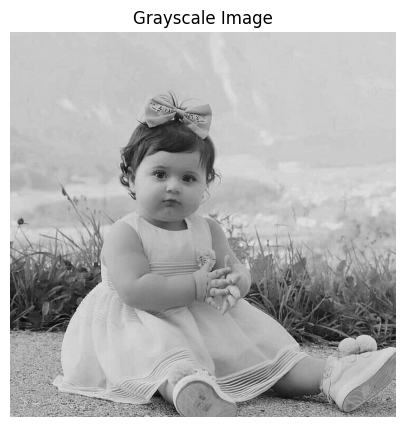

In [ ]:
gray = to_grayscale(image)

print('Grayscale shape:', gray.shape)
print('Minimum intensity:', gray.min())
print('Maximum intensity:', gray.max())
show_image(gray, 'Grayscale Image')

## Binary Threshold

إذا كانت قيمة البكسل أكبر من Threshold تصبح 255، وإلا تصبح 0.

Unique values: [  0 255]


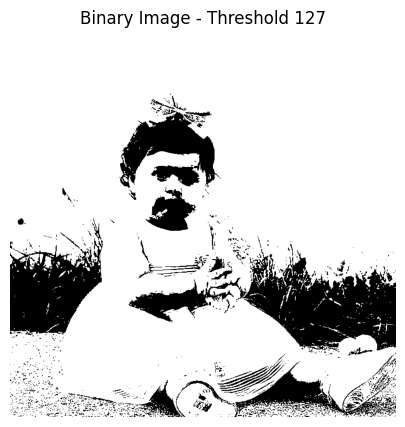

In [ ]:
threshold_value = 127
binary = apply_binary_threshold(gray, threshold_value)

print('Unique values:', np.unique(binary))
show_image(binary, f'Binary Image - Threshold {threshold_value}')

## مقارنة قيم Threshold مختلفة

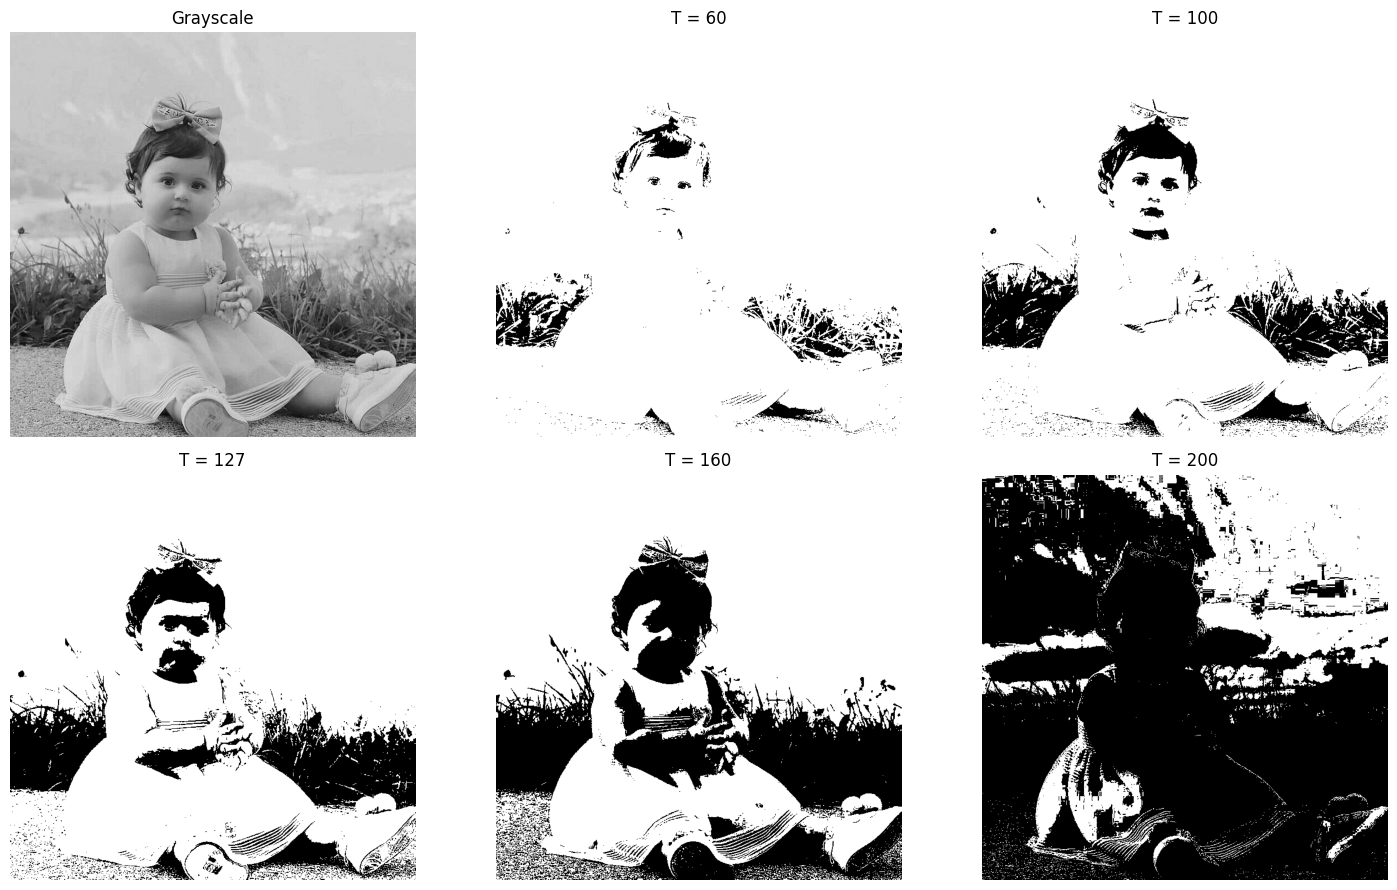

In [ ]:
threshold_values = [60, 100, 127, 160, 200]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()
axes[0].imshow(gray, cmap='gray')
axes[0].set_title('Grayscale')

for index, value in enumerate(threshold_values, start=1):
    result = apply_binary_threshold(gray, value)
    axes[index].imshow(result, cmap='gray')
    axes[index].set_title(f'T = {value}')

for axis in axes:
    axis.axis('off')

plt.tight_layout()
plt.show()

## Threshold يدوي باستخدام NumPy

توضح هذه الخلية منطق العملية بدل الاعتماد على دالة OpenCV فقط.

Manual result equals OpenCV result: True


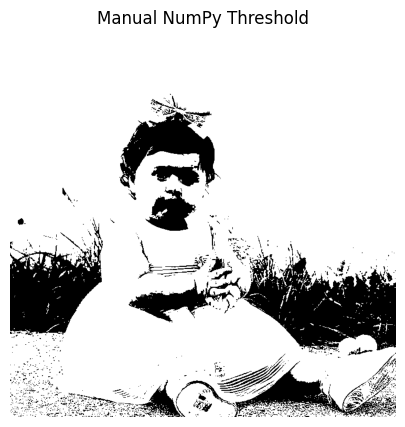

In [ ]:
manual_binary = np.where(gray > threshold_value, 255, 0).astype(np.uint8)
opencv_binary = apply_binary_threshold(gray, threshold_value)

are_equal = np.array_equal(manual_binary, opencv_binary)
print('Manual result equals OpenCV result:', are_equal)
show_image(manual_binary, 'Manual NumPy Threshold')

## حفظ النتائج

In [ ]:

original_path = OUTPUT_DIR / '01_original.png'
gray_path = OUTPUT_DIR / '01_grayscale.png'
binary_path = OUTPUT_DIR / '01_binary.png'

saved_original = cv2.imwrite(str(original_path), image)
saved_gray = cv2.imwrite(str(gray_path), gray)
saved_binary = cv2.imwrite(str(binary_path), binary)

print('Original saved:', saved_original, original_path)
print('Grayscale saved:', saved_gray, gray_path)
print('Binary saved:', saved_binary, binary_path)

Original saved: True /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/01_original.png
Grayscale saved: True /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/01_grayscale.png
Binary saved: True /content/drive/MyDrive/VisionStudio_Android_ImageProcessing/04_Outputs/Images/01_binary.png


## الربط بتطبيق Android

سيتم تحويل الوظائف السابقة لاحقًا إلى Kotlin باستخدام:

- `Imgproc.cvtColor()` بدل `cv2.cvtColor()`.
- `Imgproc.threshold()` بدل `cv2.threshold()`.
- `Imgcodecs.imwrite()` أو MediaStore بدل `cv2.imwrite()`.

بهذا نحتفظ بالخوارزمية نفسها، ويتغير فقط أسلوب كتابتها والتعامل مع ملفات Android.

## تمرين

1. ارفع صورة حقيقية وجرّب قيم Threshold مختلفة.
2. حدّد القيمة التي تفصل الجسم عن الخلفية بصورة أفضل.
3. قارن حجم الصورة الملونة بحجم مصفوفة Grayscale.